# 01 · Portfolio KPIs and exploratory analysis

**Question:** what does the portfolio look like, and which behaviours go with default?

Data: UCI *Default of Credit Card Clients* (Yeh and Lien, 2009). 30,000 card holders
in Taiwan, April to September 2005. Amounts are in New Taiwan dollars (NT$).
The target is default in October 2005.

The KPIs are computed in SQL (`sql/02_portfolio_kpis.sql`) against a SQLite copy of the
cleaned data. Run `python src/prepare_data.py` first.

In [1]:
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

con = sqlite3.connect(ROOT / "data" / "portfolio.db")
df = pd.read_csv(ROOT / "data" / "clean" / "credit_card_clients_clean.csv")


def run_named_queries(path):
    """Return {query_name: DataFrame} for a file of '-- name:' blocks."""
    text = Path(path).read_text()
    out = {}
    for block in re.split(r"^-- name: ", text, flags=re.M)[1:]:
        name, sql = block.split("\n", 1)
        out[name.strip()] = pd.read_sql(sql, con)
    return out


kpi = run_named_queries(ROOT / "sql" / "02_portfolio_kpis.sql")
kpi["portfolio_overview"]

,customers,default_rate_pct,total_limit_ntd_m,total_balance_ntd_m,portfolio_utilisation_pct
0,30000,22.12,5024.5,1537.4,30.6


## Default rate by current repayment status
Arrears in September are the clearest warning sign.

In [2]:
status = kpi["default_rate_by_current_status"]
status

,september_status,customers,default_rate_pct
0,Paid in full / no use,8445,15.6
1,"Revolving, up to date",14737,12.8
2,1 month late,3688,33.9
3,2 months late,2667,69.1
4,3+ months late,463,71.9


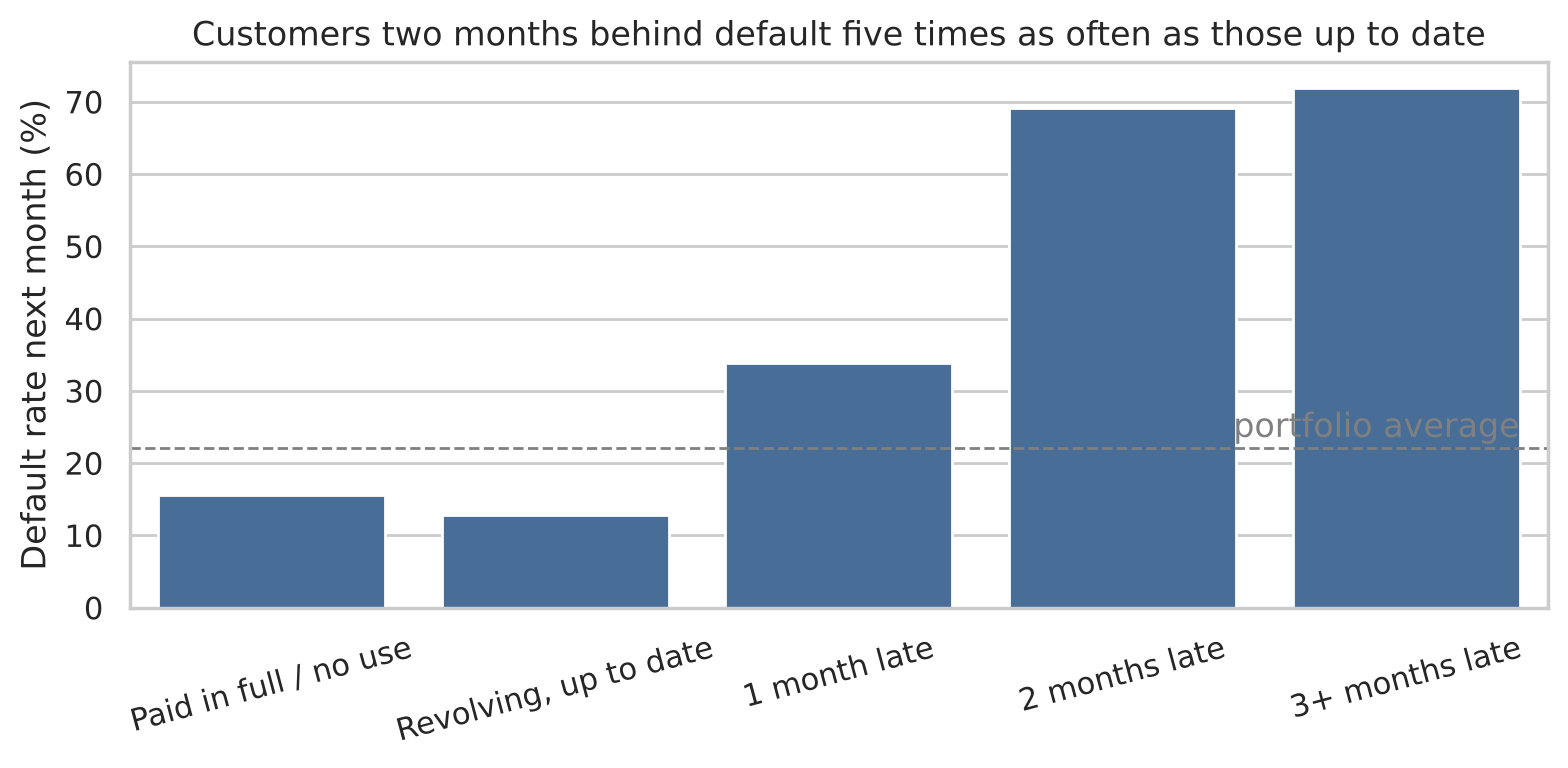

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=status, x="september_status", y="default_rate_pct", color="#3b6ea5", ax=ax)
ax.axhline(df["DEFAULT_NEXT_MONTH"].mean() * 100, ls="--", c="grey", lw=1)
ax.text(4.4, df["DEFAULT_NEXT_MONTH"].mean() * 100 + 1.5, "portfolio average", ha="right", color="grey")
ax.set(xlabel="", ylabel="Default rate next month (%)",
       title="Customers two months behind default five times as often as those up to date")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(IMG / "default_rate_by_status.png", dpi=150)
plt.show()

In [4]:
late2 = df.loc[df["PAY_1"] >= 2, "DEFAULT_NEXT_MONTH"].mean()
not_late = df.loc[df["PAY_1"] <= 0, "DEFAULT_NEXT_MONTH"].mean()
print(f"Default rate, 2+ months late in September: {late2:.1%}")
print(f"Default rate, not late in September:       {not_late:.1%}")
print(f"Ratio: {late2 / not_late:.1f}x")

Default rate, 2+ months late in September: 69.6%
Default rate, not late in September:       13.8%
Ratio: 5.0x


## Utilisation
Default rises with utilisation, but the effect is much weaker than arrears.

In [5]:
kpi["default_rate_by_utilisation_band"]

,utilisation_band,customers,default_rate_pct
0,1: <30%,14792,18.3
1,2: 30-50%,2834,22.5
2,3: 50-80%,4394,26.3
3,4: 80-100%,5857,25.5
4,5: 100%+,2123,30.1


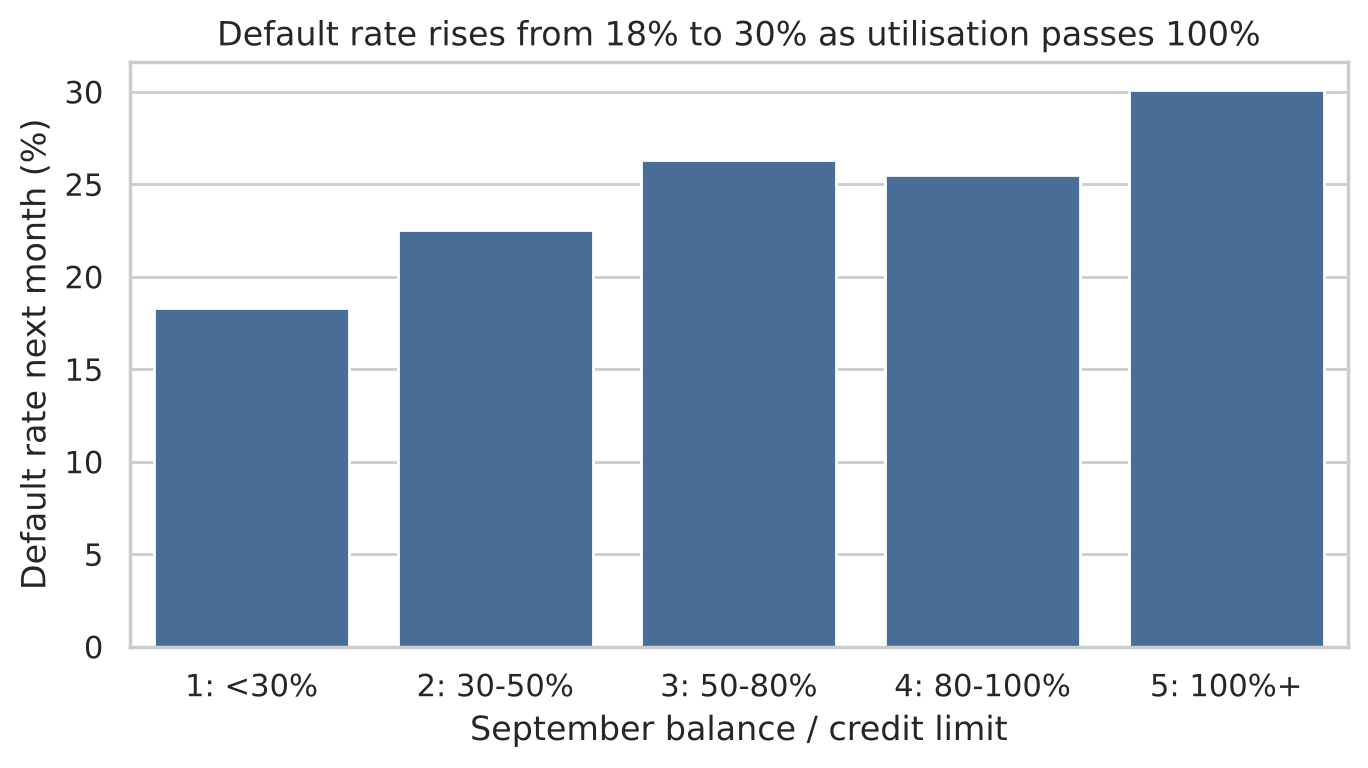

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
u = kpi["default_rate_by_utilisation_band"]
sns.barplot(data=u, x="utilisation_band", y="default_rate_pct", color="#3b6ea5", ax=ax)
ax.set(xlabel="September balance / credit limit", ylabel="Default rate next month (%)",
       title="Default rate rises from 18% to 30% as utilisation passes 100%")
plt.tight_layout()
plt.savefig(IMG / "default_rate_by_utilisation.png", dpi=150)
plt.show()

## Roll rates (August to September)
A data-quality note: in this dataset the "1 month late" status almost never appears for
August to April (`PAY_2` to `PAY_6`). Only 28 customers were 1 month late in August.
Roll rates out of that bucket are therefore not reliable. This is a known quirk of the
UCI file.

In [7]:
roll = kpi["delinquency_roll_rates"].pivot(index="aug_bucket", columns="sep_bucket",
                                           values="pct_of_aug_bucket").fillna(0)
roll

sep_bucket,0 current,1 month,2 months,3+ months
aug_bucket,,,,
0 current,88.9,7.2,3.9,0.0
1 month,0.0,100.0,0.0,0.0
2 months,10.0,42.6,40.5,6.9
3+ months,11.4,31.5,17.6,39.5


## Age, credit limit and exposure

In [8]:
kpi["default_rate_by_age_band"]

,age_band,customers,default_rate_pct,avg_limit_ntd
0,21-29,9618,22.8,124209.0
1,30-39,11238,20.3,197001.0
2,40-49,6464,23.0,180786.0
3,50+,2680,25.3,166937.0


In [9]:
kpi["limit_band_exposure_share"]

,limit_band,customers,default_rate_pct,balance_share_pct,cumulative_balance_share_pct
0,1: <50k,4311,36.1,4.3,4.3
1,2: 50k-150k,10979,25.2,31.3,35.6
2,3: 150k-300k,9593,16.8,37.5,73.0
3,4: 300k+,5117,13.7,27.0,100.0


## Correlation of behaviour features with default

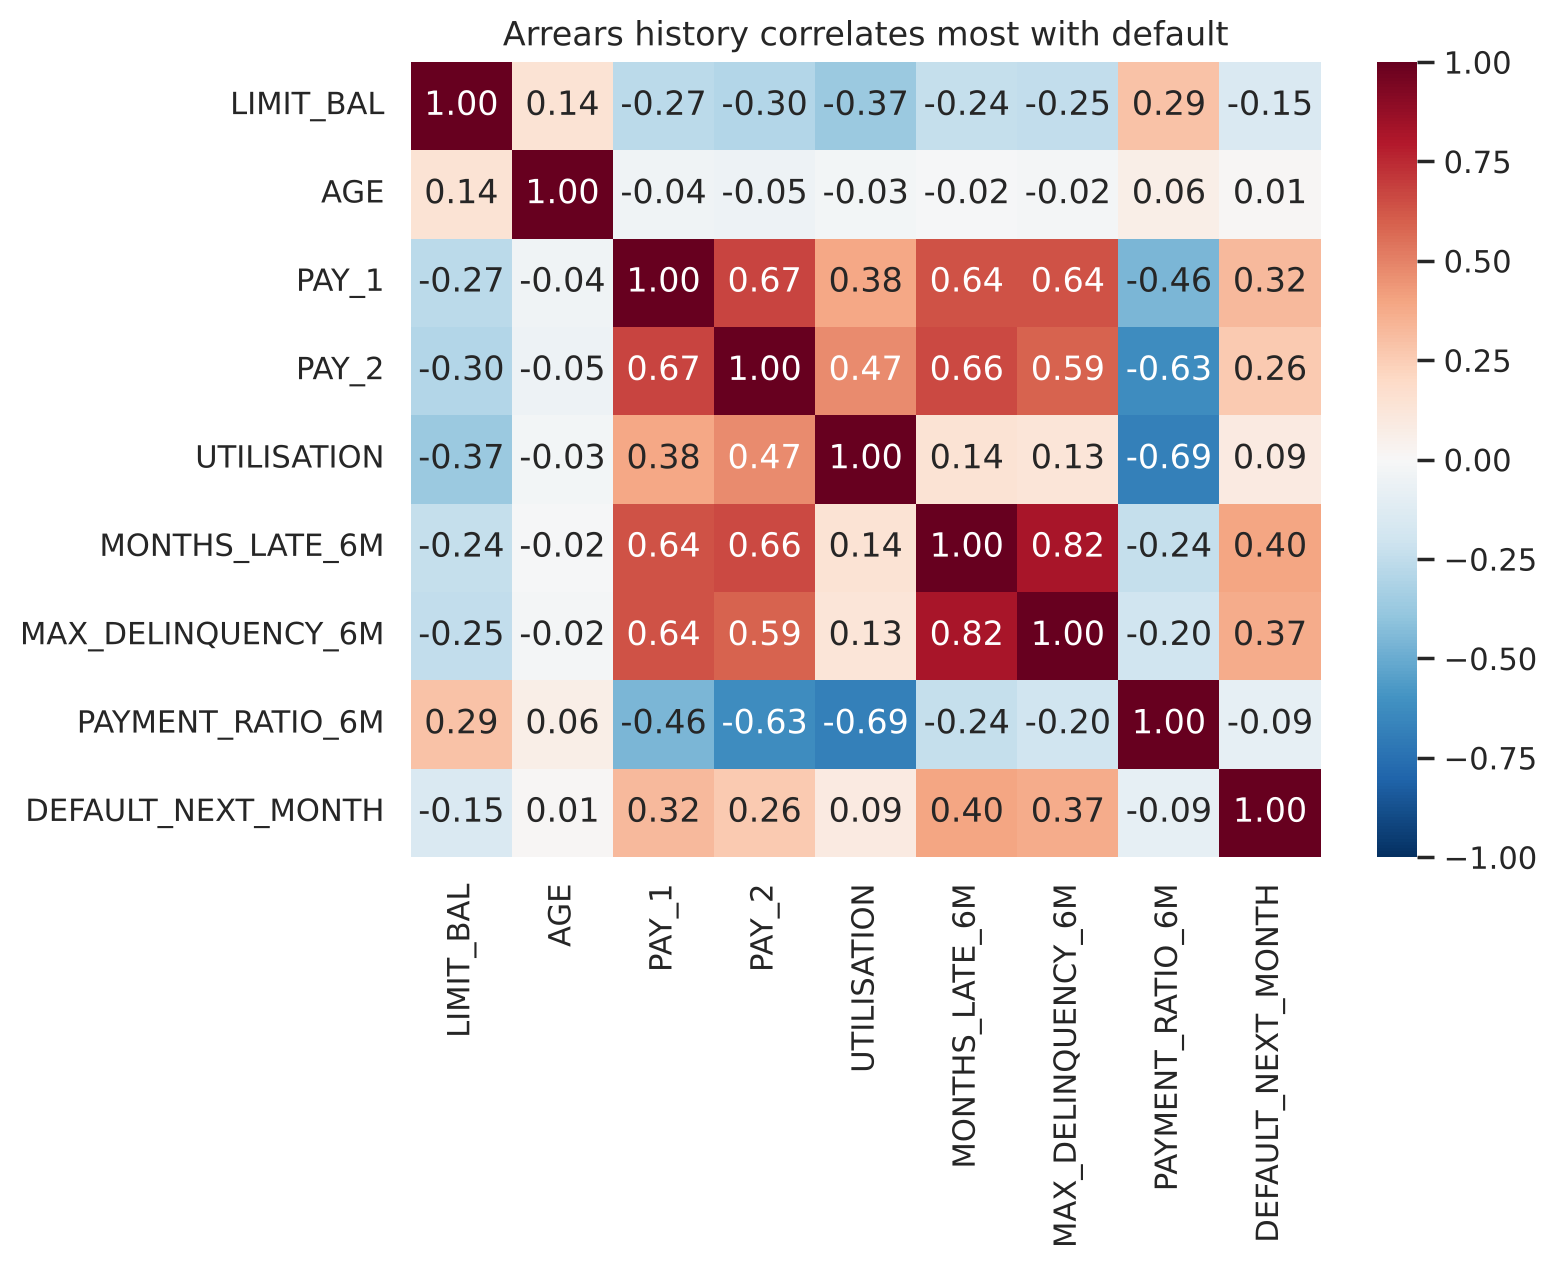

MONTHS_LATE_6M        0.398
MAX_DELINQUENCY_6M    0.370
PAY_1                 0.325
PAY_2                 0.264
UTILISATION           0.086
AGE                   0.014
PAYMENT_RATIO_6M     -0.091
LIMIT_BAL            -0.154
Name: DEFAULT_NEXT_MONTH, dtype: float64

In [10]:
cols = ["LIMIT_BAL", "AGE", "PAY_1", "PAY_2", "UTILISATION", "MONTHS_LATE_6M",
        "MAX_DELINQUENCY_6M", "PAYMENT_RATIO_6M", "DEFAULT_NEXT_MONTH"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Arrears history correlates most with default")
plt.tight_layout()
plt.savefig(IMG / "correlation_heatmap.png", dpi=150)
plt.show()
corr["DEFAULT_NEXT_MONTH"].drop("DEFAULT_NEXT_MONTH").sort_values(ascending=False).round(3)